## Assignment 1: Implementing an MLP using Numpy

## FF:

In [76]:
import math

def sigmoid(x):
  return 1 / (1 + math.exp(-x))

def derivative_sigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

def softmax(o1, o2):
    e1 = math.exp(o1)
    e2 = math.exp(o2)
    return e1 / (e1 + e2), e2 / (e1 + e2)

def cross_entropy(y1, y2, t1, t2):
    return -(t1 * math.log(y1) + t2 * math.log(y2))


In [77]:
x = [1, -1]
w = [[1,1,1,], [-1,-1,-1]]
k = [0, 0, 0]
h = [0, 0, 0]
v = [[1, 1], [-1, -1], [-1, -1]] # v[0,0], v[0,1], v[1,0], v[1,1]
o = [0, 0]
y = [0, 0]
t = [1, 0]
b = [0, 0, 0]
c = [0, 0]

In [78]:
def forward(x, w, v, b, c):
    k = [0.0] * 3
    h = [0.0] * 3
    o = [0.0] * 2

    for j in range(0, 3):
        for i in range(0, 2):
            k[j] += w[i][j] * x[i]
        k[j] += b[j]

    for i in range(0, 3):
        h[i] = sigmoid(k[i])

    for j in range(0, 2):
        for i in range(0, 3):
            o[j] += h[i] * v[i][j]
        o[j] += c[j]

    y = softmax(o[0], o[1])

    return k, h, o, y




### Backpropagation

In [79]:
def backpropagation(x, t, k, h, y, v):
    dL_dy = [0, 0]
    dy_do = [[0, 0], [0, 0]]
    dL_do = [0, 0]
    dL_dh = [0, 0 ,0]
    dh_dk = [0, 0 ,0]
    dL_dk = [0, 0 ,0]
    dk_dw = [[0,0,0], [0,0,0]]
    dL_dw = [[0,0,0], [0,0,0]]
    dL_dv = [[0, 0], [0, 0],[0, 0]]
    dL_dc = [0, 0]
    dL_db = [0, 0, 0]

    for i in range(0, 2):
        dL_dy[i] = -t[i] / y[i]

    for i in range(2):
        for j in range(2):
            if i == j:
                dy_do[i][j] = y[i] * (1 - y[i])
            else:
                dy_do[i][j] = -y[i]*y[j]
            dL_do[j] +=  dL_dy[i] * dy_do[i][j] 

    for i in range(0, 3):
        for j in range(0, 2):
            dL_dv[i][j] = dL_do[j]*h[i]

    for i in range(2):
        for j in range(3):
            dL_dh[j] += v[j][i] * dL_do[i]

    for i in range(3):
        dh_dk[i] = derivative_sigmoid(k[i])
        dL_dk[i] = dh_dk[i] * dL_dh[i]

    for i in range(2):
        for j in range(3):
            dk_dw[i][j] = x[i]
            dL_dw[i][j] = dL_dk[j] * x[i]

    for i in range(2):
        dL_dc[i] =  dL_do[i]

    for i in range(3):
        dL_db[i] = dL_dk[i]
        
    return dL_dw, dL_dv, dL_db, dL_dc
        


## Training on dataset

In [80]:
from data import load_synth

(xtrain, ytrain), (xval, yval), num_cls = load_synth()

In [8]:
print(ytrain[:5])
print(xtrain.shape, ytrain.shape)
print(xval.shape, yval.shape)
print(xtrain[:5])
print(xval[:5])
print(xtrain.min())
print(xtrain.max())


[1 1 1 1 0]
(60000, 2) (60000,)
(10000, 2) (10000,)
[[ 1.76405235  0.40015721]
 [ 0.97873798  2.2408932 ]
 [ 1.86755799 -0.97727788]
 [ 0.95008842 -0.15135721]
 [-0.10321885  0.4105985 ]]
[[ 1.85658976 -1.5049403 ]
 [ 0.91501945 -1.24619226]
 [-0.65684037  0.85767918]
 [-0.1446762  -1.48769544]
 [ 0.02272977  0.6311182 ]]
-4.852117653180117
4.285855641221728


## Normalize data

In [81]:
import numpy as np

# min and max only from training data to avoid data leakage
min_train = np.min(xtrain, axis=0)
max_train = np.max(xtrain, axis=0)


normalized_xtrain = (xtrain - min_train) / (max_train  - min_train)
normalized_xval= (xval -  min_train) / (max_train  - min_train)


In [64]:
print(normalized_xtrain.min(), normalized_xtrain.max())


0.0 1.0


In [82]:
np.random.seed(42)

w = np.random.normal(0, 1, size=(2, 3))
v = np.random.normal(0, 1, size=(3, 2))
b = [0, 0, 0]
c = [0, 0]


In [ ]:
initial_weight = w[0][0]
loss_history = []
learning_rate = 0.003

for epoch in range(100):
    epoch_loss = 0

    for index in range(len(normalized_xtrain)):
        x = normalized_xtrain[index]
        label = int(ytrain[index])
        t = [0, 0]
        t[label] = 1
        k, h, o, y = forward(x, w, v, b, c)
        loss = cross_entropy(y[0], y[1], t[0], t[1])
        
        dL_dw, dL_dv, dL_db, dL_dc = backpropagation(x, t, k, h, y, v)

        for i in range(2):
            for j in range(3):
                w[i][j] -= learning_rate * dL_dw[i][j]

        for i in range(3):
            for j in range(2):
                v[i][j] -= learning_rate * dL_dv[i][j]

        for i in range(3):
            b[i] -= learning_rate * dL_db[i]

        for i in range(2):
            c[i] -= learning_rate * dL_dc[i]

        epoch_loss += loss

    average_loss = epoch_loss / len(normalized_xtrain)
    loss_history.append(average_loss)
    print(f"Epoch {epoch + 1}: Loss = {average_loss:.4f}")


Epoch 1: Loss = 0.6872
Epoch 2: Loss = 0.6871
Epoch 3: Loss = 0.6870
Epoch 4: Loss = 0.6869
Epoch 5: Loss = 0.6869
Epoch 6: Loss = 0.6867
Epoch 7: Loss = 0.6866
Epoch 8: Loss = 0.6864
Epoch 9: Loss = 0.6862
Epoch 10: Loss = 0.6858
Epoch 11: Loss = 0.6854
Epoch 12: Loss = 0.6848
Epoch 13: Loss = 0.6841
Epoch 14: Loss = 0.6830
Epoch 15: Loss = 0.6815
Epoch 16: Loss = 0.6794
Epoch 17: Loss = 0.6762
Epoch 18: Loss = 0.6713
Epoch 19: Loss = 0.6637
Epoch 20: Loss = 0.6514
Epoch 21: Loss = 0.6307
Epoch 22: Loss = 0.5967
Epoch 23: Loss = 0.5456
Epoch 24: Loss = 0.4810
Epoch 25: Loss = 0.4140
Epoch 26: Loss = 0.3554
Epoch 27: Loss = 0.3096
Epoch 28: Loss = 0.2759
Epoch 29: Loss = 0.2518
Epoch 30: Loss = 0.2345
Epoch 31: Loss = 0.2220
Epoch 32: Loss = 0.2129
Epoch 33: Loss = 0.2061
Epoch 34: Loss = 0.2010
Epoch 35: Loss = 0.1970
Epoch 36: Loss = 0.1933
Epoch 37: Loss = 0.1892
Epoch 38: Loss = 0.1833
Epoch 39: Loss = 0.1740
Epoch 40: Loss = 0.1604
Epoch 41: Loss = 0.1438
Epoch 42: Loss = 0.1281
E

In [35]:
print(initial_weight)
print(w[i][j])

0.4967141530112327
12.169109442545553


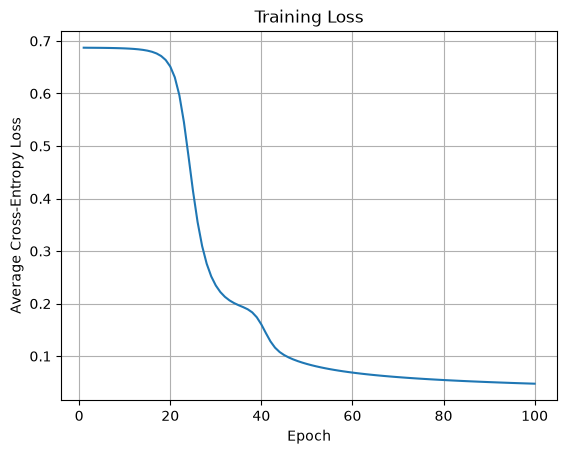

In [52]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots()
ax.plot(range(1, len(loss_history) + 1), loss_history)

ax.set_xlabel("Epoch")
ax.set_ylabel("Average Cross-Entropy Loss")
ax.set_title("Training Loss")
ax.grid(True)

plt.show()            



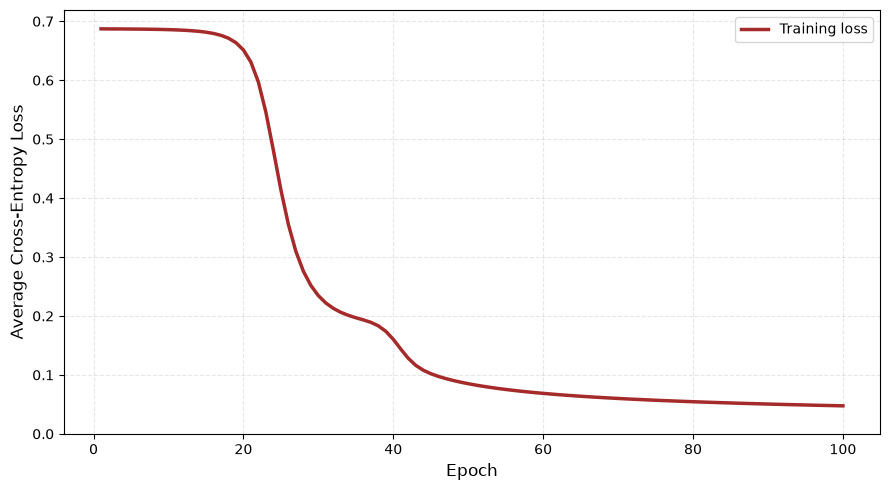

In [57]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

epochs = range(1, len(loss_history) + 1)

ax.plot(epochs, loss_history,
        color="brown",
        linewidth=2.5,
        label="Training loss")

ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Average Cross-Entropy Loss", fontsize=12)


ax.set_ylim(bottom=0)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [58]:
correct = 0

for index in range(len(normalized_xval)):
    x = normalized_xval[index]
    label = int(yval[index])

    k, h, o, y = forward(x, w, v, b, c)

    prediction = 0 if y[0] > y[1] else 1

    if prediction == label:
        correct += 1

accuracy = correct / len(normalized_xval)

print(f"Validation accuracy: {accuracy:.2%}")

Validation accuracy: 99.20%


In [46]:
print("Number of epochs:", len(loss_history))
print("First 5:", loss_history[:5])
print("Last 5:", loss_history[-5:])

Number of epochs: 50
First 5: [0.04698180220797025, 0.046727070512672, 0.046477612586908745, 0.04623323997994358, 0.045993773941555086]
Last 5: [0.039001602331785984, 0.03887804076540219, 0.03875603263867935, 0.03863554616456311, 0.03851655048164929]
